# SafeFlow — Do speed differences improve congestion warnings?

Test whether **changes in speed over time** and **speed gaps between the current, upstream, and downstream detectors** are more useful than absolute speed measurements. Compare 10-, 15-, 20-, and 30-minute endpoint predictions on the same D12 northbound observations and temporal fold as the horizon experiment. The previous notebooks remain unchanged.

Four controlled feature representations:

| Representation | Speed information |
|---|---|
| `raw_speeds` | Current speed and 5/10/15/30-minute lags at each of the three detectors |
| `differences_only` | Temporal changes at all three detectors plus current local–upstream and local–downstream gaps; no absolute speed levels |
| `level_plus_differences` | The differences above plus current local speed as an absolute anchor |
| `raw_plus_differences` | Raw speeds and the difference features together |

All four receive the **same non-speed predictors and missing-measurement indicators**. This isolates speed representation. Every fitted model at a given horizon uses identical training rows and is scored on identical evaluation rows. Models: logistic regression and Random Forest. The forests use **100 trees for this exploratory comparison**, with the prior depth/leaf/class-weight settings; confirm promising results with 300 trees and the other temporal folds before choosing a final model.

Hypotheses: negative temporal changes indicate deceleration; a positive local-minus-downstream gap means downstream traffic is slower, potentially exposing a developing bottleneck. The reverse spatial sign may describe different congestion configurations. These are predictive hypotheses, not causal assumptions.

## Findings from the completed experiment

Full first-fold development run: **46 stations, four horizons, two model types, four representations, and three evaluation cohorts**. Random Forest uses **100 trees per fit**; the comparison changes the speed representation while preserving the non-speed context, missingness indicators, training rows, and evaluation rows.

**Random Forest average precision — native cohort:**

| Horizon | Raw speeds | Differences only | Local level + differences | Raw speeds + differences |
|---|---:|---:|---:|---:|
| 10 min | 0.1734 | 0.1606 | 0.1805 | 0.1618 |
| 15 min | 0.2428 | 0.2121 | 0.2476 | 0.2328 |
| 20 min | 0.2921 | 0.2518 | 0.2985 | 0.2793 |
| 30 min | 0.3449 | 0.3103 | 0.3507 | 0.3417 |

**Precision at the ≥80% recall target — native cohort:**

| Horizon | Raw speeds | Differences only | Local level + differences | Raw speeds + differences |
|---|---:|---:|---:|---:|
| 10 min | 2.88% | 2.75% | 3.50% | 3.15% |
| 15 min | 4.85% | 4.23% | 5.67% | 5.10% |
| 20 min | 6.76% | 5.15% | 7.25% | 6.96% |
| 30 min | 9.68% | 7.52% | 9.20% | 9.86% |

**Measured takeaway:** Current local speed plus differences improves native Random Forest average precision at 10, 15, 20, 30 minutes. At the recall target, precision improves at 10, 15, 20 minutes and decreases at 30 minutes. Differences-only lowers both average precision and warning precision at every native horizon. Retaining a local speed anchor is a promising representation to confirm, especially for shorter windows; it is not a universally better warning policy.

**Paired effects:**

- **Logistic regression, `differences_only`:** relative AP changes versus raw speeds: 10 min -45.0%, 15 min -33.1%, 20 min -31.7%, 30 min -28.7%.
- **Logistic regression, `level_plus_differences`:** relative AP changes versus raw speeds: 10 min +4.2%, 15 min +2.4%, 20 min +0.1%, 30 min +0.4%.
- **Logistic regression, `raw_plus_differences`:** relative AP changes versus raw speeds: 10 min +4.7%, 15 min +2.6%, 20 min +1.8%, 30 min +1.8%.
- **Random Forest, `differences_only`:** relative AP changes versus raw speeds: 10 min -7.4%, 15 min -12.6%, 20 min -13.8%, 30 min -10.0%.
- **Random Forest, `level_plus_differences`:** relative AP changes versus raw speeds: 10 min +4.1%, 15 min +2.0%, 20 min +2.2%, 30 min +1.7%.
- **Random Forest, `raw_plus_differences`:** relative AP changes versus raw speeds: 10 min -6.7%, 15 min -4.1%, 20 min -4.4%, 30 min -0.9%.

Interpret the AP and warning-precision tables together; an AP gain need not improve the chosen warning policy. The cohort-sensitivity plot below shows whether each paired effect persists on identical cross-horizon origins and on complete speed measurements. Improvements on one validation fold do not establish significance or final-holdout performance.

With complete readings, anchored differences and raw levels contain the same information. Any gain is evidence about the model's representation, regularization, tree-splitting behavior, or treatment of missing inputs—not additional detector measurements. Differences-only removes absolute speed levels from the predictors. These feature bundles combine temporal and spatial changes, so they do not identify which component supplies a benefit.

This static summary describes the saved all-station, first-fold, 100-tree run. Update it after changing configuration. Before adopting a representation, confirm with 300 trees, the other temporal folds, and episode-level warning evaluation. The final holdout has not been used.

Saved tables and figures: `results/speed_difference_comparison/2026-10-29_143906_459767`.


**Cohort qualification.** For the anchored-difference Random Forest, common-origin AP changes versus raw speeds are -9.4%, -5.5%, -1.8%, and +10.2% at 10/15/20/30 minutes, while precision at the recall target increases on that cohort at all four horizons. On complete-measurement native origins, AP improves modestly at all horizons, but precision improves only at 10/15/20 minutes and falls at 30 minutes, matching the full native pattern. The candidate benefit therefore depends on both evaluation population and operational metric; it should not be presented as a universal improvement.


In [1]:
from pathlib import Path
from datetime import datetime
from time import perf_counter
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, precision_recall_curve, confusion_matrix)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data").is_dir() and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Start this notebook in the SafeFlow project or a subdirectory")
PROCESSED_DIR = ROOT / "data" / "processed"
FEATURE_FILE = PROCESSED_DIR / "main.parquet"
FOLDS_FILE = PROCESSED_DIR / "temporal_folds.json"
STATION_ORDER_FILE = PROCESSED_DIR / "i5_nb_station_order.csv"
RESULTS_DIR = ROOT / "results" / "speed_difference_comparison"

HORIZONS = [10, 15, 20, 30]
FOLD_INDEX = 0  # same development fold as the original notebook; try 1, 2, 3 later
FREE_FLOW_THRESHOLD, CONGESTED_THRESHOLD = 50.0, 40.0
REGIME_THRESHOLD, TARGET_MIN_OBSERVED = 45.0, 80
TARGET_RECALL = 0.80
RF_TREES, RF_DEPTH, RF_MIN_LEAF = 100, 12, 10
RANDOM_STATE = 42
RF_N_JOBS = -1  # reduce if memory is limited
STATION_IDS = None  # None = all 46 northbound stations; subset only for a smoke run

# Preserve the original analysis's names so the feature definitions are identical.
TIMESTAMP_COL, STATION_COL = "Timestamp", "Station"
SPEED_COL, FLOW_COL, OCC_COL, OBS_COL = "Avg Speed", "Total Flow", "Avg Occupancy", "% Observed"
assert HORIZONS and len(set(HORIZONS)) == len(HORIZONS)
assert all(h > 0 and h % 5 == 0 for h in HORIZONS)
assert 0 < TARGET_RECALL <= 1
for file in [FEATURE_FILE, FOLDS_FILE]:
    if not file.exists():
        raise FileNotFoundError(f"Missing {file}. Run the export cell in data_and_features.ipynb first")
fold_config = json.loads(FOLDS_FILE.read_text(encoding="utf-8"))
selected_fold = fold_config["folds"][FOLD_INDEX]
train_start = pd.Timestamp(fold_config["train_start"])
val_start, val_end = pd.Timestamp(selected_fold["val_start"]), pd.Timestamp(selected_fold["val_end"])
test_start = pd.Timestamp(fold_config["test_start"])
assert train_start < val_start < val_end <= test_start
print("Project:", ROOT, flush=True)
print("Horizons:", HORIZONS, "minutes", flush=True)
print("Training labels before:", val_start, "Validation labels before:", val_end, flush=True)
print("Final holdout starts:", test_start, "— excluded from this experiment", flush=True)

Project: C:\Erdos\Project\safeflow
Horizons: [10, 15, 20, 30] minutes
Training labels before: 2023-07-01 00:00:00 Validation labels before: 2024-01-01 00:00:00
Final holdout starts: 2025-07-01 00:00:00 — excluded from this experiment


## 1. Load the development data and exact local history

Use the first fold (January–June 2023 training; July–December 2023 validation), the same ≥50 mph current free-flow and ≤40 mph future congestion boundaries, and ≥80% future observation coverage. Labels are checked exactly at the selected horizon, not anywhere within the interval. The July–December 2025 holdout is excluded. Only weekday daytime observations are present in the prepared source.

In [2]:
print("Loading saved mainline observations…", flush=True)
raw_columns = ["timestamp", "station", "speed", "flow", "occupancy", "pct_observed", "direction"]
raw = pd.read_parquet(FEATURE_FILE, columns=raw_columns, engine="pyarrow",
                      filters=[("timestamp", ">=", train_start), ("timestamp", "<", val_end)])
raw["timestamp"] = pd.to_datetime(raw["timestamp"], errors="raise")
raw = raw.loc[raw["direction"].astype(str).str.upper().str.strip().eq("N")].copy()
if STATION_IDS is not None:
    raw = raw.loc[raw["station"].isin(STATION_IDS)].copy()
corridor = raw.rename(columns={"timestamp": TIMESTAMP_COL, "station": STATION_COL,
    "speed": SPEED_COL, "flow": FLOW_COL, "occupancy": OCC_COL, "pct_observed": OBS_COL})
base_cols = [STATION_COL, TIMESTAMP_COL, SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]
base = corridor[base_cols].copy()
for column in [SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]:
    base[column] = pd.to_numeric(base[column], errors="coerce")
duplicate_rows = int(base.duplicated([STATION_COL, TIMESTAMP_COL]).sum())
if duplicate_rows:
    base = base.groupby([STATION_COL, TIMESTAMP_COL], as_index=False)[
        [SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]].mean()
base = base.sort_values([TIMESTAMP_COL, STATION_COL]).reset_index(drop=True)
if base.empty:
    raise ValueError("No northbound observations in the selected development period")
assert base[TIMESTAMP_COL].max() < val_end <= test_start
del raw, corridor
print(f"Loaded {len(base):,} rows, {base[STATION_COL].nunique()} stations; duplicates averaged: {duplicate_rows}", flush=True)
display(base.head())

Loading saved mainline observations…
Loaded 2,006,336 rows, 46 stations; duplicates averaged: 0


,Station,Timestamp,Avg Speed,Total Flow,Avg Occupancy,% Observed
0,1205045,2023-01-02 06:00:00,71.7,168.0,0.0298,80.0
1,1205071,2023-01-02 06:00:00,59.9,188.0,0.0359,0.0
2,1205088,2023-01-02 06:00:00,69.6,193.0,0.0293,80.0
3,1205135,2023-01-02 06:00:00,71.5,191.0,0.0285,100.0
4,1205152,2023-01-02 06:00:00,60.2,212.0,0.0394,100.0


In [3]:
features = base.copy().rename(columns={
    SPEED_COL: "speed_now",
    FLOW_COL: "flow_now",
    OCC_COL: "occupancy_now",
    OBS_COL: "observed_now",
})

lag_source = base.copy()

def add_exact_lag(frame, source, columns, lag_min, suffix):
    lag = source[[STATION_COL, TIMESTAMP_COL] + columns].copy()
    lag[TIMESTAMP_COL] = lag[TIMESTAMP_COL] + pd.Timedelta(minutes=lag_min)
    lag = lag.rename(columns={c: f"{c}_{suffix}" for c in columns})
    return frame.merge(lag, on=[STATION_COL, TIMESTAMP_COL], how="left", validate="one_to_one")

for lag_min in [5, 10, 15, 30]:
    features = add_exact_lag(features, lag_source, [SPEED_COL], lag_min, f"lag_{lag_min}min")
for lag_min in [5, 15, 30]:
    features = add_exact_lag(features, lag_source, [FLOW_COL, OCC_COL], lag_min, f"lag_{lag_min}min")

features = features.rename(columns={
    f"{SPEED_COL}_lag_5min": "speed_lag_5",
    f"{SPEED_COL}_lag_10min": "speed_lag_10",
    f"{SPEED_COL}_lag_15min": "speed_lag_15",
    f"{SPEED_COL}_lag_30min": "speed_lag_30",
    f"{FLOW_COL}_lag_5min": "flow_lag_5",
    f"{FLOW_COL}_lag_15min": "flow_lag_15",
    f"{FLOW_COL}_lag_30min": "flow_lag_30",
    f"{OCC_COL}_lag_5min": "occ_lag_5",
    f"{OCC_COL}_lag_15min": "occ_lag_15",
    f"{OCC_COL}_lag_30min": "occ_lag_30",
})

speed_recent = ["speed_now", "speed_lag_5", "speed_lag_10", "speed_lag_15", "speed_lag_30"]
features["speed_trend_15"] = features["speed_now"] - features["speed_lag_15"]
features["speed_recent_mean"] = features[speed_recent].mean(axis=1)
features["speed_recent_std"] = features[speed_recent].std(axis=1)
features["flow_trend_15"] = features["flow_now"] - features["flow_lag_15"]
features["occupancy_trend_15"] = features["occupancy_now"] - features["occ_lag_15"]

hour_fraction = features[TIMESTAMP_COL].dt.hour + features[TIMESTAMP_COL].dt.minute / 60
features["hour_sin"] = np.sin(2 * np.pi * hour_fraction / 24)
features["hour_cos"] = np.cos(2 * np.pi * hour_fraction / 24)
features["is_weekend"] = (features[TIMESTAMP_COL].dt.dayofweek >= 5).astype(int)

print("Feature table shape:", features.shape)
display(features.head())

Feature table shape: (2006336, 24)


,Station,Timestamp,speed_now,flow_now,occupancy_now,observed_now,speed_lag_5,speed_lag_10,speed_lag_15,speed_lag_30,flow_lag_5,occ_lag_5,flow_lag_15,occ_lag_15,flow_lag_30,occ_lag_30,speed_trend_15,speed_recent_mean,speed_recent_std,flow_trend_15,occupancy_trend_15,hour_sin,hour_cos,is_weekend
0,1205045,2023-01-02 06:00:00,71.7,168.0,0.0298,80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71.7,NaN,NaN,NaN,1.0,6.123234e-17,0
1,1205071,2023-01-02 06:00:00,59.9,188.0,0.0359,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.9,NaN,NaN,NaN,1.0,6.123234e-17,0
2,1205088,2023-01-02 06:00:00,69.6,193.0,0.0293,80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69.6,NaN,NaN,NaN,1.0,6.123234e-17,0
3,1205135,2023-01-02 06:00:00,71.5,191.0,0.0285,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71.5,NaN,NaN,NaN,1.0,6.123234e-17,0
4,1205152,2023-01-02 06:00:00,60.2,212.0,0.0394,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.2,NaN,NaN,NaN,1.0,6.123234e-17,0


## 2. Match upstream and downstream measurements at the same historical times

Metadata order increases northbound. Use the preceding detector as upstream and the following one as downstream; do not sort station IDs as a substitute for physical order. Match by **detector and exact timestamp**, never by row offset or nearest future reading. Current flow, occupancy, and observation quality at both neighbors are included as shared context in every representation.

The first/last corridor detector has no neighbor on one side. Missing records remain missing and are handled by training-only median imputation. Missingness indicators are identical in all representations; complete-measurement evaluation below checks whether conclusions change when no speed inputs require imputation.

In [4]:
if not STATION_ORDER_FILE.exists():
    raise FileNotFoundError(f"Missing physical station order: {STATION_ORDER_FILE}")
order = pd.read_csv(STATION_ORDER_FILE)
required = {STATION_COL, "corridor_order"}
if not required.issubset(order):
    raise ValueError(f"Station-order file requires {required}")
if order[STATION_COL].isna().any() or not order[STATION_COL].is_unique:
    raise ValueError("Station IDs in physical order must be present and unique")
if order.corridor_order.isna().any() or not order.corridor_order.is_unique:
    raise ValueError("Corridor positions must be present and unique")
order = order.sort_values("corridor_order").copy()
order["upstream_id"] = order[STATION_COL].shift(1)
order["downstream_id"] = order[STATION_COL].shift(-1)
if not features[STATION_COL].isin(order[STATION_COL]).all():
    raise ValueError("Some observed stations lack metadata order; resolve before comparing neighbors")
neighbor_map = order.set_index(STATION_COL)
observations = base.set_index([STATION_COL, TIMESTAMP_COL])[[SPEED_COL, FLOW_COL, OCC_COL, OBS_COL]]

def at_neighbor(detector_ids, lag_minutes):
    keys = pd.MultiIndex.from_arrays([detector_ids.to_numpy(),
        (features[TIMESTAMP_COL] - pd.Timedelta(minutes=lag_minutes)).to_numpy()],
        names=[STATION_COL, TIMESTAMP_COL])
    return observations.reindex(keys).reset_index(drop=True)

X = pd.DataFrame(index=features.index)
local_lookup = {0: "speed_now", 5: "speed_lag_5", 10: "speed_lag_10", 15: "speed_lag_15", 30: "speed_lag_30"}
for lag, column in local_lookup.items():
    X[f"local_speed_{lag}"] = features[column].astype("float32")
for side in ["upstream", "downstream"]:
    ids = features[STATION_COL].map(neighbor_map[f"{side}_id"])
    for lag in local_lookup:
        matched = at_neighbor(ids, lag)
        X[f"{side}_speed_{lag}"] = matched[SPEED_COL].to_numpy(dtype="float32")
        if lag == 0:
            for raw_col, name in [(FLOW_COL, "flow"), (OCC_COL, "occupancy"), (OBS_COL, "observed")]:
                X[f"{side}_{name}_now"] = matched[raw_col].to_numpy(dtype="float32")
    print(f"Matched {side} measurements", flush=True)
del matched

context_cols = ["flow_now", "flow_lag_5", "flow_lag_15", "flow_lag_30", "flow_trend_15",
                "occupancy_now", "occ_lag_5", "occ_lag_15", "occ_lag_30", "occupancy_trend_15",
                "observed_now", "hour_sin", "hour_cos", "is_weekend"]
for column in context_cols:
    X[column] = features[column].astype("float32")
context_cols += [f"{side}_{name}_now" for side in ["upstream", "downstream"] for name in ["flow", "occupancy", "observed"]]
raw_speed_cols = [f"{side}_speed_{lag}" for side in ["local", "upstream", "downstream"] for lag in local_lookup]
X[raw_speed_cols] = X[raw_speed_cols].replace([np.inf, -np.inf], np.nan)
complete_measurements = X[raw_speed_cols].notna().all(axis=1)
missing_cols = []
for column in raw_speed_cols:
    indicator = f"{column}_missing"
    X[indicator] = X[column].isna().astype("float32")
    missing_cols.append(indicator)

delta_cols = []
for side in ["local", "upstream", "downstream"]:
    for lag in [5, 10, 15, 30]:
        name = f"{side}_change_{lag}min"
        X[name] = X[f"{side}_speed_0"] - X[f"{side}_speed_{lag}"]
        delta_cols.append(name)
for side in ["upstream", "downstream"]:
    name = f"local_minus_{side}_now"
    X[name] = X["local_speed_0"] - X[f"{side}_speed_0"]
    delta_cols.append(name)

shared_cols = context_cols + missing_cols
REPRESENTATIONS = {
    "raw_speeds": shared_cols + raw_speed_cols,
    "differences_only": shared_cols + delta_cols,
    "level_plus_differences": shared_cols + ["local_speed_0"] + delta_cols,
    "raw_plus_differences": shared_cols + raw_speed_cols + delta_cols,
}
# Verify that anchored differences can reconstruct all raw speeds when observed.
check = X.loc[complete_measurements]
for side in ["local", "upstream", "downstream"]:
    anchor = check.local_speed_0 if side == "local" else check.local_speed_0 - check[f"local_minus_{side}_now"]
    for lag in [5, 10, 15, 30]:
        np.testing.assert_allclose(anchor - check[f"{side}_change_{lag}min"], check[f"{side}_speed_{lag}"], atol=1e-4)
del check
for name, columns in REPRESENTATIONS.items():
    assert len(columns) == len(set(columns))
    print(name, len(columns), "features")
print("Complete three-detector speed history:", f"{complete_measurements.mean():.1%}")
display(X[["local_speed_0", "local_change_15min", "local_minus_upstream_now", "local_minus_downstream_now"]].head())
# Free the larger historical feature frame; label construction needs only these keys.
features = features[[STATION_COL, TIMESTAMP_COL, "speed_now"]].copy()

Matched upstream measurements
Matched downstream measurements
raw_speeds 50 features
differences_only 49 features
level_plus_differences 50 features
raw_plus_differences 64 features
Complete three-detector speed history: 92.2%


,local_speed_0,local_change_15min,local_minus_upstream_now,local_minus_downstream_now
0,71.699997,NaN,NaN,11.799995
1,59.900002,NaN,-11.799995,-9.699997
2,69.599998,NaN,9.699997,-1.900002
3,71.500000,NaN,1.900002,11.299999
4,60.200001,NaN,-11.299999,-9.999996


**What a difference feature means.** `local_change_15min = local speed(t) − local speed(t−15)`; negative means local speed has fallen. `local_minus_downstream_now = local speed(t) − downstream speed(t)`; positive means traffic is slower downstream. Upstream/downstream temporal changes use their own earlier observations, not future measurements.

**Same information, different representation.** With complete observations, current local speed plus these differences reconstructs all 15 raw speed levels. Adding differences to raw levels adds no independent measurements. For linear models, improvements mainly reflect regularization/representation and missing-data handling; trees may benefit from directly splitting on contrasts that otherwise require several axis-aligned splits. Median imputation can break the algebraic equivalence, so inspect the complete-measurement subset as well. The differences-only version deliberately removes absolute speed level, which may discard useful context.

## 3. Keep labels, temporal boundaries, and scoring rows fixed

Native and common-origin cohorts have the same definitions as in the horizon notebook. Add `complete_measurements`: native validation origins with all 15 raw speed readings available. Every representation is evaluated on exactly the same rows within each horizon/cohort; no representation gets to discard its difficult missing inputs. Models train on native training rows, including rows requiring imputation. Shared missingness flags and non-speed inputs are always available to every representation.

Common-origin selection uses future labels and is a retrospective sensitivity check; complete-measurement selection uses measurements at or before the forecast origin. Neither subset changes training membership.

In [5]:
lookup = base.set_index([STATION_COL, TIMESTAMP_COL])[[SPEED_COL, OBS_COL]]
origin_time = features[TIMESTAMP_COL]
labels, native_train, native_val = {}, {}, {}
population_rows = []

def exact_future(horizon):
    keys = pd.MultiIndex.from_arrays(
        [features[STATION_COL].to_numpy(), (origin_time + pd.Timedelta(minutes=horizon)).to_numpy()],
        names=[STATION_COL, TIMESTAMP_COL])
    future = lookup.reindex(keys)
    return pd.DataFrame({"future_speed": future[SPEED_COL].to_numpy(),
                         "future_observed": future[OBS_COL].to_numpy()}, index=features.index)

for horizon in HORIZONS:
    frame = exact_future(horizon)
    frame["label"] = np.where(frame["future_speed"] <= CONGESTED_THRESHOLD, 1.0,
                               np.where(frame["future_speed"] >= FREE_FLOW_THRESHOLD, 0.0, np.nan))
    eligible = ((features["speed_now"] >= FREE_FLOW_THRESHOLD)
                & (frame["future_observed"] >= TARGET_MIN_OBSERVED) & frame["label"].notna())
    target_time = origin_time + pd.Timedelta(minutes=horizon)
    frame["eligible"] = eligible
    labels[horizon] = frame
    native_train[horizon] = eligible & (origin_time >= train_start) & (target_time < val_start)
    native_val[horizon] = eligible & (origin_time >= val_start) & (target_time < val_end)

common_eligible = np.logical_and.reduce([labels[h]["eligible"].to_numpy() for h in HORIZONS])
common_train = common_eligible & (origin_time >= train_start) & (origin_time + pd.Timedelta(minutes=max(HORIZONS)) < val_start)
common_val = common_eligible & (origin_time >= val_start) & (origin_time + pd.Timedelta(minutes=max(HORIZONS)) < val_end)
if not common_val.any():
    raise ValueError("No common-origin validation observations remain")

for horizon in HORIZONS:
    for cohort, train_mask, val_mask in [("native", native_train[horizon], native_val[horizon]),
                                         ("common_origins", common_train, common_val)]:
        y = labels[horizon]["label"]
        population_rows.append(dict(horizon_min=horizon, cohort=cohort,
            train_eligible_rows=int(train_mask.sum()), validation_rows=int(val_mask.sum()),
            validation_positives=int(y.loc[val_mask].sum()), validation_prevalence=y.loc[val_mask].mean()))
populations = pd.DataFrame(population_rows)
display(populations.round(5))
print("Common-origin training counts above describe intersection eligibility; models train on native rows.", flush=True)

,horizon_min,cohort,train_eligible_rows,validation_rows,validation_positives,validation_prevalence
0,10,native,451089,324294,737,0.00227
1,10,common_origins,419693,299852,441,0.00147
2,15,native,445335,319958,1574,0.00492
3,15,common_origins,419693,299852,505,0.00168
4,20,native,440409,316229,2500,0.00791
5,20,common_origins,419693,299852,578,0.00193
6,30,native,431692,309745,4183,0.01350
7,30,common_origins,419693,299852,1092,0.00364


Common-origin training counts above describe intersection eligibility; models train on native rows.


In [6]:
cohort_counts = []
for horizon in HORIZONS:
    for cohort, mask in [("native", native_val[horizon]), ("common_origins", common_val),
                         ("complete_measurements", native_val[horizon] & complete_measurements)]:
        y = labels[horizon].loc[mask, "label"]
        cohort_counts.append(dict(horizon_min=horizon, cohort=cohort, n=int(mask.sum()),
                                 positives=int(y.sum()), prevalence=y.mean()))
cohort_counts = pd.DataFrame(cohort_counts)
display(cohort_counts.round(5))

,horizon_min,cohort,n,positives,prevalence
0,10,native,324294,737,0.00227
1,10,common_origins,299852,441,0.00147
2,10,complete_measurements,293738,717,0.00244
3,15,native,319958,1574,0.00492
4,15,common_origins,299852,505,0.00168
5,15,complete_measurements,289638,1527,0.00527
6,20,native,316229,2500,0.00791
7,20,common_origins,299852,578,0.00193
8,20,complete_measurements,286114,2416,0.00844
9,30,native,309745,4183,0.01350


## 4. Fit the paired experiments

Every horizon uses the same native training rows for all four representations. Imputation/scaling use training observations only. Compare average precision (ranking), precision at the 80% recall target, false warnings, and F1. Each representation's warning threshold is selected on validation; all scores remain development estimates. Pure differences still use the current-speed threshold to define the eligible forecasting population, but absolute speed is absent from that model's predictor columns.

There are **16 logistic and 16 Random Forest fits**. The 100-tree setting is a controlled exploratory budget, not a direct comparison with the earlier 300-tree scores. Progress prints before each fit and metrics checkpoint after each fit. Keep the tree count identical across representations when repeating with more trees.

In [7]:
def score_metrics(y, prob, threshold):
    predicted = prob >= threshold
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    prevalence = float(np.mean(y))
    ap = average_precision_score(y, prob) if np.sum(y) else np.nan
    return dict(n=len(y), positives=int(np.sum(y)), prevalence=prevalence,
                PR_AUC=ap, AP_lift=ap / prevalence if prevalence else np.nan,
                ROC_AUC=roc_auc_score(y, prob) if np.unique(y).size == 2 else np.nan,
                Precision=precision_score(y, predicted, zero_division=0),
                Recall=recall_score(y, predicted, zero_division=0),
                F1=f1_score(y, predicted, zero_division=0),
                true_positives=int(tp), false_positives=int(fp), false_negatives=int(fn), true_negatives=int(tn),
                warnings_per_1000=1000 * float(np.mean(predicted)),
                false_warnings_per_true_onset=fp / tp if tp else np.nan)

def choose_threshold(y, prob):
    if np.unique(y).size < 2:
        return np.nan
    precision, recall, thresholds = precision_recall_curve(y, prob)
    table = pd.DataFrame(dict(threshold=thresholds, precision=precision[:-1], recall=recall[:-1]))
    eligible = table.loc[table.recall >= TARGET_RECALL]
    return float(eligible.sort_values(["precision", "threshold"], ascending=False).iloc[0].threshold) if len(eligible) else np.nan


run_dir = RESULTS_DIR / datetime.now().strftime("%Y-%m-%d_%H%M%S_%f")
run_dir.mkdir(parents=True, exist_ok=False)
result_rows, paired_curves = [], []
print("Experiment:", run_dir, flush=True)
for horizon in HORIZONS:
    train_mask = native_train[horizon]
    y_train = labels[horizon].loc[train_mask, "label"].astype(int)
    if y_train.nunique() != 2:
        raise ValueError(f"{horizon} min training lacks both classes")
    masks = {"native": native_val[horizon], "common_origins": common_val,
             "complete_measurements": native_val[horizon] & complete_measurements}
    val_index = features.index[native_val[horizon]]
    for model_name in ["Logistic regression", "Random Forest"]:
        for representation, columns in REPRESENTATIONS.items():
            started = perf_counter()
            print(f"[{horizon} min] {model_name} / {representation}: fitting {len(y_train):,} rows", flush=True)
            if model_name == "Logistic regression":
                model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                                  ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
            else:
                model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                  ("model", RandomForestClassifier(n_estimators=RF_TREES, max_depth=RF_DEPTH,
                                    min_samples_leaf=RF_MIN_LEAF, class_weight="balanced_subsample",
                                    random_state=RANDOM_STATE, n_jobs=RF_N_JOBS))])
            model.fit(X.loc[train_mask, columns], y_train)
            probability = pd.Series(model.predict_proba(X.loc[val_index, columns])[:, 1], index=val_index)
            for cohort, mask in masks.items():
                y = labels[horizon].loc[mask, "label"].astype(int).to_numpy()
                if len(y) == 0 or np.unique(y).size != 2:
                    print(f"Skipping {horizon} min / {cohort}: insufficient classes", flush=True)
                    continue
                prob = probability.loc[features.index[mask]].to_numpy()
                threshold = choose_threshold(y, prob)
                for operating_point, cutoff in [("default_0.5", 0.5), ("target_recall", threshold)]:
                    result_rows.append(dict(horizon_min=horizon, cohort=cohort, model=model_name,
                        representation=representation, feature_count=len(columns),
                        operating_point=operating_point, threshold=cutoff,
                        **score_metrics(y, prob, cutoff)))
                p, r, _ = precision_recall_curve(y, prob)
                positions = np.unique(np.linspace(0, len(p)-1, min(500, len(p))).astype(int))
                paired_curves.extend(dict(horizon_min=horizon, cohort=cohort, model=model_name,
                    representation=representation, precision=float(p[j]), recall=float(r[j])) for j in positions)
            results = pd.DataFrame(result_rows)
            results.to_csv(run_dir / "classifier_metrics.csv", index=False)
            print(f"  complete in {perf_counter()-started:.1f}s; checkpoint saved", flush=True)
            del model
curves = pd.DataFrame(paired_curves)
assert results.groupby(["horizon_min", "cohort", "model", "operating_point"]).n.nunique().eq(1).all()
display(results.loc[results.operating_point.eq("target_recall"),
    ["horizon_min", "cohort", "model", "representation", "n", "prevalence", "PR_AUC", "Precision", "Recall", "F1"]].round(4))

Experiment: C:\Erdos\Project\safeflow\results\speed_difference_comparison\2026-10-29_143906_459767
[10 min] Logistic regression / raw_speeds: fitting 451,089 rows
  complete in 8.1s; checkpoint saved
[10 min] Logistic regression / differences_only: fitting 451,089 rows
  complete in 10.0s; checkpoint saved
[10 min] Logistic regression / level_plus_differences: fitting 451,089 rows
  complete in 8.1s; checkpoint saved
[10 min] Logistic regression / raw_plus_differences: fitting 451,089 rows
  complete in 13.9s; checkpoint saved
[10 min] Random Forest / raw_speeds: fitting 451,089 rows
  complete in 32.6s; checkpoint saved
[10 min] Random Forest / differences_only: fitting 451,089 rows
  complete in 37.2s; checkpoint saved
[10 min] Random Forest / level_plus_differences: fitting 451,089 rows
  complete in 35.0s; checkpoint saved
[10 min] Random Forest / raw_plus_differences: fitting 451,089 rows
  complete in 40.1s; checkpoint saved
[15 min] Logistic regression / raw_speeds: fitting 445,

,horizon_min,cohort,model,representation,n,prevalence,PR_AUC,Precision,Recall,F1
1,10,native,Logistic regression,raw_speeds,324294,0.0023,0.0390,0.0214,0.8019,0.0418
3,10,common_origins,Logistic regression,raw_speeds,299852,0.0015,0.0369,0.0208,0.8005,0.0405
5,10,complete_measurements,Logistic regression,raw_speeds,293738,0.0024,0.0430,0.0220,0.8006,0.0427
7,10,native,Logistic regression,differences_only,324294,0.0023,0.0214,0.0132,0.8005,0.0260
9,10,common_origins,Logistic regression,differences_only,299852,0.0015,0.0161,0.0103,0.8005,0.0204
...,...,...,...,...,...,...,...,...,...,...
183,30,common_origins,Random Forest,level_plus_differences,299852,0.0036,0.2258,0.0241,0.8022,0.0468
185,30,complete_measurements,Random Forest,level_plus_differences,280014,0.0143,0.3511,0.0919,0.8000,0.1648
187,30,native,Random Forest,raw_plus_differences,309745,0.0135,0.3417,0.0986,0.8001,0.1755
189,30,common_origins,Random Forest,raw_plus_differences,299852,0.0036,0.2017,0.0239,0.8022,0.0465


## 5. Compare each representation with the paired raw-speed baseline

Positive AP change means better ranking on identical examples. Positive precision change at the recall target means more true positives among issued warnings, at roughly the same detection rate. A model may improve one metric and worsen the other. Precision changes are in **percentage points**; relative AP changes are percentages. Read both models and all cohorts before interpreting a feature representation as better.

,horizon_min,cohort,model,representation,PR_AUC,AP_relative_change_pct,precision80_change_pp
0,10,native,Logistic regression,raw_speeds,0.0390,0.0000,0.0000
3,10,native,Logistic regression,differences_only,0.0214,-45.0236,-0.8216
6,10,native,Logistic regression,level_plus_differences,0.0406,4.2135,-0.0091
9,10,native,Logistic regression,raw_plus_differences,0.0408,4.6605,-0.0101
12,10,native,Random Forest,raw_speeds,0.1734,0.0000,0.0000
15,10,native,Random Forest,differences_only,0.1606,-7.4272,-0.1313
18,10,native,Random Forest,level_plus_differences,0.1805,4.0816,0.6223
21,10,native,Random Forest,raw_plus_differences,0.1618,-6.7121,0.2656
24,15,native,Logistic regression,raw_speeds,0.0604,0.0000,0.0000
27,15,native,Logistic regression,differences_only,0.0404,-33.1404,-1.4370


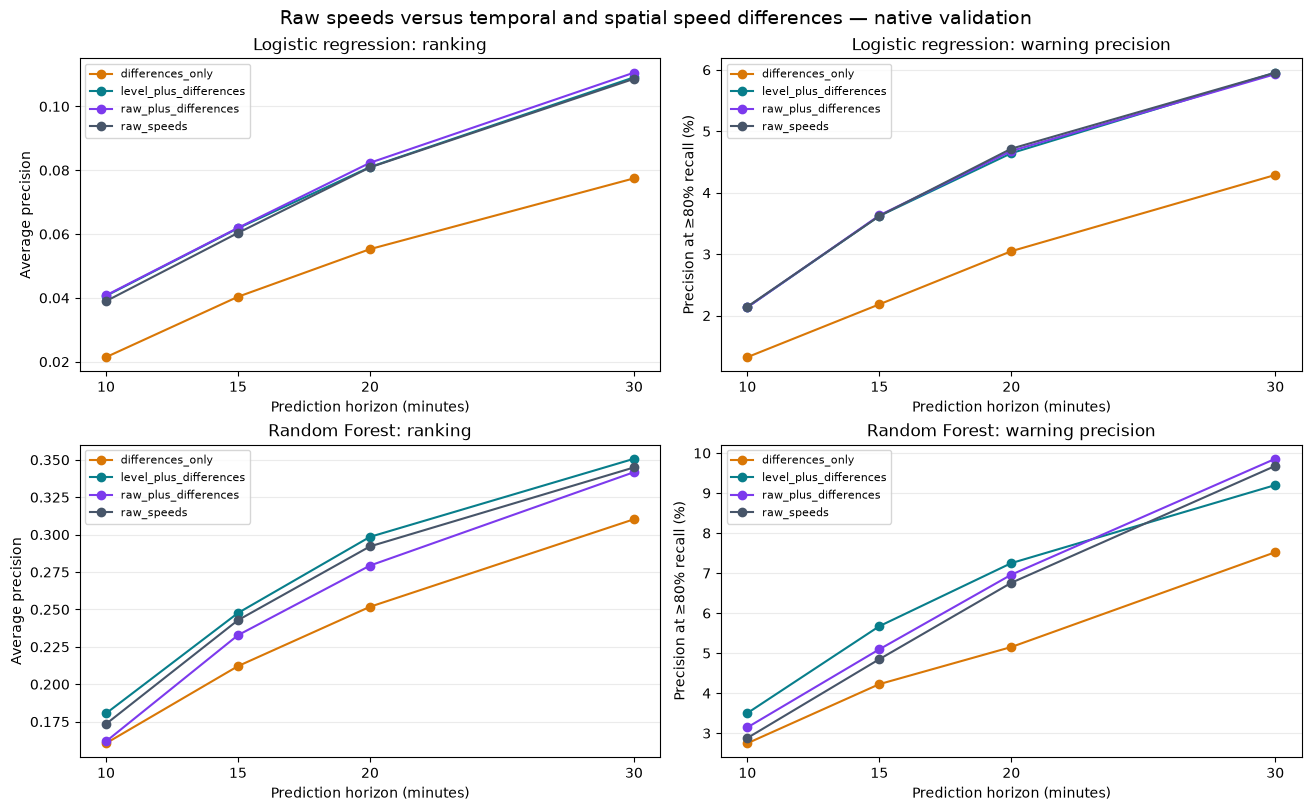

In [8]:
ranking = results.loc[results.operating_point.eq("default_0.5")].copy()
policy = results.loc[results.operating_point.eq("target_recall")].copy()
keys = ["horizon_min", "cohort", "model"]
baseline = ranking.loc[ranking.representation.eq("raw_speeds"), keys + ["PR_AUC", "n"]].rename(
    columns={"PR_AUC": "baseline_AP", "n": "baseline_n"})
comparison = ranking.merge(baseline, on=keys, validate="many_to_one")
assert comparison.n.eq(comparison.baseline_n).all()
comparison["AP_change"] = comparison.PR_AUC - comparison.baseline_AP
comparison["AP_relative_change_pct"] = 100 * comparison.AP_change / comparison.baseline_AP
baseline_policy = policy.loc[policy.representation.eq("raw_speeds"), keys + ["Precision"]].rename(columns={"Precision": "baseline_precision80"})
precision_comparison = policy.merge(baseline_policy, on=keys, validate="many_to_one")
precision_comparison["precision80_change_pp"] = 100 * (precision_comparison.Precision - precision_comparison.baseline_precision80)
comparison = comparison.merge(precision_comparison[keys + ["representation", "precision80_change_pp"]],
                              on=keys + ["representation"], validate="one_to_one")
display(comparison.loc[comparison.cohort.eq("native"), keys + ["representation", "PR_AUC", "AP_relative_change_pct", "precision80_change_pp"]].round(4))

colors = {"raw_speeds": "#475569", "differences_only": "#d97706", "level_plus_differences": "#087e8b", "raw_plus_differences": "#7c3aed"}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
for row, model_name in enumerate(["Logistic regression", "Random Forest"]):
    subset = ranking.loc[ranking.model.eq(model_name) & ranking.cohort.eq("native")]
    operating = policy.loc[policy.model.eq(model_name) & policy.cohort.eq("native")]
    for representation, group in subset.groupby("representation"):
        group = group.sort_values("horizon_min")
        axes[row, 0].plot(group.horizon_min, group.PR_AUC, marker="o", label=representation, color=colors[representation])
    for representation, group in operating.groupby("representation"):
        group = group.sort_values("horizon_min")
        axes[row, 1].plot(group.horizon_min, 100*group.Precision, marker="o", label=representation, color=colors[representation])
    axes[row, 0].set(title=f"{model_name}: ranking", ylabel="Average precision")
    axes[row, 1].set(title=f"{model_name}: warning precision", ylabel="Precision at ≥80% recall (%)")
    for ax in axes[row]:
        ax.set(xlabel="Prediction horizon (minutes)", xticks=HORIZONS)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(fontsize=8)
fig.suptitle("Raw speeds versus temporal and spatial speed differences — native validation", fontsize=14)
fig.savefig(run_dir / "speed_representation_comparison.png", dpi=170, bbox_inches="tight")
fig.savefig(run_dir / "speed_representation_comparison.svg", bbox_inches="tight")
plt.show()

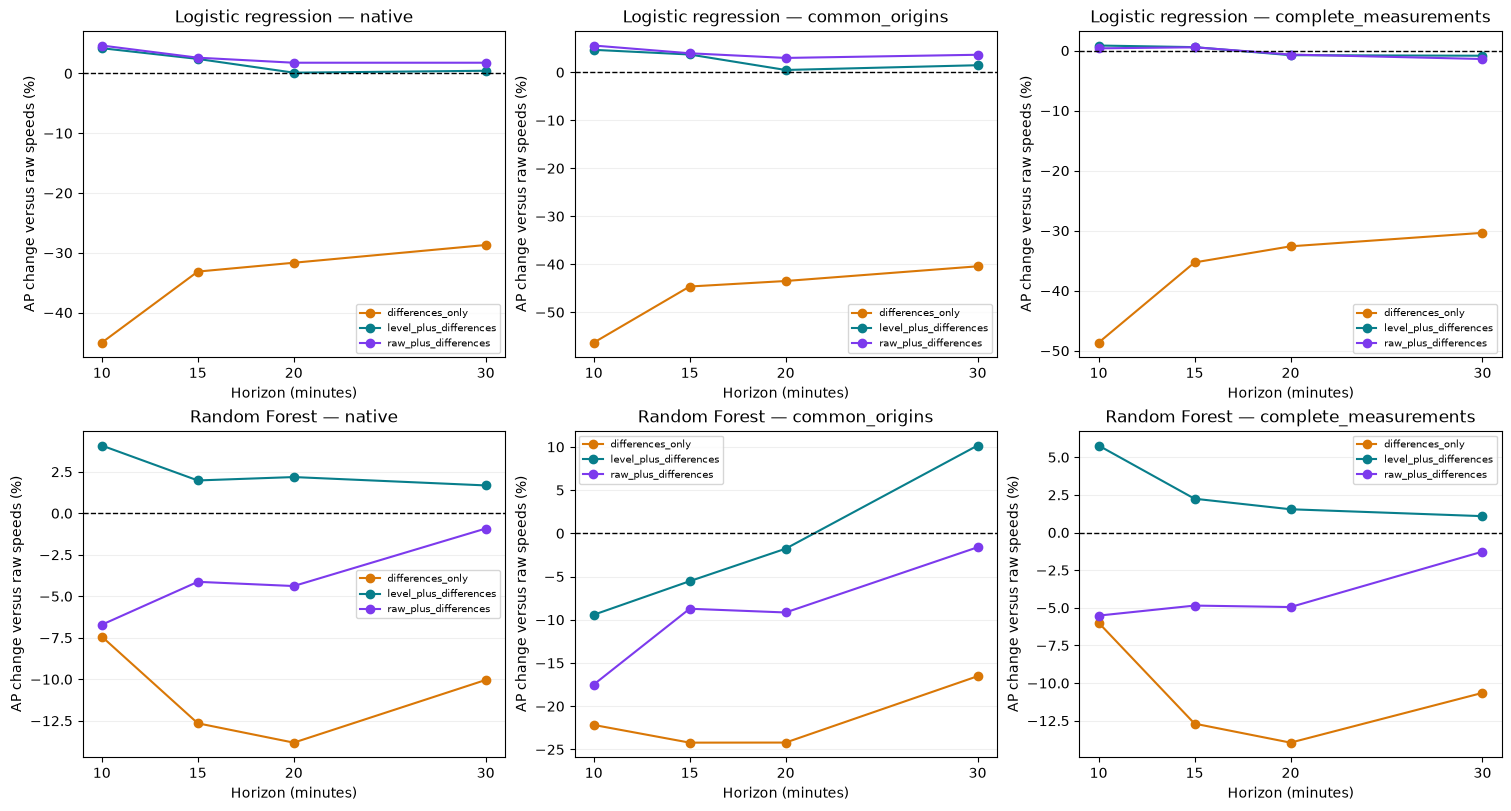

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for row, model_name in enumerate(["Logistic regression", "Random Forest"]):
    for column, cohort in enumerate(["native", "common_origins", "complete_measurements"]):
        ax = axes[row, column]
        sub = comparison.loc[comparison.model.eq(model_name) & comparison.cohort.eq(cohort) & comparison.representation.ne("raw_speeds")]
        for representation, group in sub.groupby("representation"):
            group = group.sort_values("horizon_min")
            ax.plot(group.horizon_min, group.AP_relative_change_pct, marker="o", color=colors[representation], label=representation)
        ax.axhline(0, color="black", linestyle="--", linewidth=1)
        ax.set(title=f"{model_name} — {cohort}", xlabel="Horizon (minutes)", ylabel="AP change versus raw speeds (%)", xticks=HORIZONS)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(fontsize=7)
fig.savefig(run_dir / "speed_difference_cohort_sensitivity.png", dpi=170, bbox_inches="tight")
plt.show()

## 6. Report measured effects and preserve the experiment

The printed findings below are computed from this run, not assumed in advance. A convincing feature change should improve ranking and warning burden across multiple horizons and temporal folds, rather than win a single score. A benefit only on imputed rows may reflect missingness handling; a benefit on complete observations supports a representation effect. Differences alone may sacrifice absolute traffic-state information. These contrasts combine temporal and spatial differences; a later temporal-only versus spatial-only ablation can identify which component drives any gain.

This is a first-fold, 100-tree screen. Models and warning thresholds are compared/tuned on the same validation period, so results can be optimistic. No statistical significance or unseen-station performance is established. Repeat with more trees and the other saved folds before changing the production feature design or evaluating the final holdout.

In [10]:
for model_name in ["Logistic regression", "Random Forest"]:
    print("\n", model_name, "— native validation")
    for horizon in sorted(HORIZONS):
        table = comparison.loc[comparison.model.eq(model_name) & comparison.cohort.eq("native") & comparison.horizon_min.eq(horizon)]
        for row in table.loc[table.representation.ne("raw_speeds")].itertuples():
            print(f"{horizon:2d} min / {row.representation}: AP {row.PR_AUC:.4f} "
                  f"({row.AP_relative_change_pct:+.1f}% versus raw); precision at recall target {row.precision80_change_pp:+.3f} pp")
config = dict(horizons=HORIZONS, fold_index=FOLD_INDEX, fold=selected_fold,
    train_start=str(train_start), test_start=str(test_start), station_ids=STATION_IDS,
    feature_file=str(FEATURE_FILE), feature_file_bytes=FEATURE_FILE.stat().st_size,
    feature_file_mtime_ns=FEATURE_FILE.stat().st_mtime_ns,
    representations=REPRESENTATIONS, target_recall=TARGET_RECALL,
    free_flow_threshold=FREE_FLOW_THRESHOLD, congested_threshold=CONGESTED_THRESHOLD,
    target_min_observed=TARGET_MIN_OBSERVED, rf_trees=RF_TREES, rf_depth=RF_DEPTH,
    rf_min_leaf=RF_MIN_LEAF, random_state=RANDOM_STATE,
    python=platform.python_version(), pandas=pd.__version__, sklearn=sklearn.__version__)
(run_dir / "configuration.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
results.to_csv(run_dir / "classifier_metrics.csv", index=False)
comparison.to_csv(run_dir / "paired_representation_comparison.csv", index=False)
cohort_counts.to_csv(run_dir / "cohort_populations.csv", index=False)
curves.to_csv(run_dir / "precision_recall_curves.csv", index=False)
order.to_csv(run_dir / "physical_station_neighbors.csv", index=False)
print("Saved experiment:", run_dir)


 Logistic regression — native validation
10 min / differences_only: AP 0.0214 (-45.0% versus raw); precision at recall target -0.822 pp
10 min / level_plus_differences: AP 0.0406 (+4.2% versus raw); precision at recall target -0.009 pp
10 min / raw_plus_differences: AP 0.0408 (+4.7% versus raw); precision at recall target -0.010 pp
15 min / differences_only: AP 0.0404 (-33.1% versus raw); precision at recall target -1.437 pp
15 min / level_plus_differences: AP 0.0618 (+2.4% versus raw); precision at recall target +0.001 pp
15 min / raw_plus_differences: AP 0.0620 (+2.6% versus raw); precision at recall target +0.011 pp
20 min / differences_only: AP 0.0553 (-31.7% versus raw); precision at recall target -1.668 pp
20 min / level_plus_differences: AP 0.0810 (+0.1% versus raw); precision at recall target -0.073 pp
20 min / raw_plus_differences: AP 0.0823 (+1.8% versus raw); precision at recall target -0.036 pp
30 min / differences_only: AP 0.0775 (-28.7% versus raw); precision at recall t